# CropGuard-Q: a quantum crop checker under attack

**Moroccan Crop Classification Challenge · Qiskit Fall Fest · EMSI × Quantum Africa** — classify Doukkala fields as **alfalfa, maize or wheat** from Sentinel-2 measurements, and answer one focused question:

> **Does adding a quantum model to a classical model add anything, especially when the data is tampered with or incomplete, compared with adding another classical model instead?**

**Run it** from the repository root (Python 3.12 as pinned; also tested on CPython 3.15):

```bash
python3.12 -m venv .venv
.venv/bin/python -m pip install -r requirements.txt         # main run
.venv/bin/python -m pip install -r requirements-noise.txt   # optional: section 6 (noise study)
.venv/bin/jupyter nbconvert --to notebook --execute --inplace notebooks/CropGuard_Q.ipynb
```

Sections 1–4 are the **main result**: exact local simulation, 8 qubits, no network, no credentials, no optional package. Sections 5–7 are **additional analysis**; each can be switched off in the next cell, and the IBM section only reads saved results unless `RUN_HARDWARE = True`.

| Part | What it does |
|---|---|
| Quantum inspector | 8-qubit ZZ-feature-map fidelity kernel, exact statevectors, then an SVM with a precomputed kernel |
| Classical inspectors | RBF SVM and random forest on the same 8 numbers |
| Vote + tamper alarm | majority label (the RBF SVM settles a three-way split); a field is **flagged** when the three are not unanimous |
| Matched control | the same pipeline with the quantum SVM replaced by a polynomial-kernel SVM tuned with the same 30-configuration budget |
| AI error-fixer | a linear regression that maps noisy similarity values back to exact ones; used only for noisy-simulator and IBM runs |

In [1]:
import json, sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from challenge.data import load_data
from challenge.classical import reference
from challenge.metrics import score
from challenge.submission import LABELS, Submission, MatchedControl, load_config, preprocessing
from challenge.kernel import QuantumKernelSVM
from challenge import guard, tune, mitigation, hardware_kernel as hk  # hardware_kernel imports IBM code only when used

RUN_TUNING = True       # ~1 min: reruns the equal-budget grid; the frozen configs/cropguard.json is used either way
RUN_ATTACK_LAB = True   # ~10 min: tampering, poisoned labels, missing bands (additional analysis)
RUN_NOISE_STUDY = True  # ~5 min, needs requirements-noise.txt; otherwise the saved study is shown
RUN_HARDWARE = False    # needs requirements-hardware.txt, QISKIT_IBM_TOKEN and approval; otherwise saved results are shown

OUT = ROOT / 'outputs'; (OUT / 'predictions').mkdir(parents=True, exist_ok=True)
L, SEEDS = list(LABELS), [0, 1, 2]
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.grid': True, 'grid.alpha': .3})
def save_show(fig, name):
    fig.savefig(OUT / f'{name}.png', dpi=150, bbox_inches='tight'); plt.show()
def timed(fn):
    t = time.perf_counter(); out = fn(); return out, time.perf_counter() - t
T0 = time.perf_counter()

tables, _, manifest, _ = load_data()  # verifies every checksum, schema and split before anything else
F = manifest['features']
X, y = tables['train'][F].to_numpy(), tables['train'].target.to_numpy()
Xv, yv = tables['validation'][F].to_numpy(), tables['validation'].target.to_numpy()
Xt = tables['test'][F].to_numpy()  # test features only: no test label exists anywhere in this repository
ids_v, ids_t = tables['validation'].sample_id.to_numpy(), tables['test'].sample_id.to_numpy()
print('Python', sys.version.split()[0], '| rows', manifest['rows'], '| inputs', F)

Python 3.15.2 | rows {'train': 914, 'validation': 150, 'test': 221} | inputs ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'NDVI']


## 1. Inputs and preprocessing

Every model receives the **13 raw features** (never IDs or spatial codes). `Submission.fit` learns `StandardScaler → PCA(8) → StandardScaler` on the training rows only, which is the recipe of the supplied `data/views/pca8.npz`; the check below confirms an exact match. Eight numbers give one number per qubit. The 8-component view carries more signal than the starter's 4-component view, but its last components carry very little variance and the second scaler stretches them to unit size. Section 5 shows that this is exactly where tampering attacks push.

In [2]:
view = np.load(ROOT / 'data/views/pca8.npz', allow_pickle=False)
prep = preprocessing().fit(X)
assert np.allclose(prep.transform(X), view['X_train']) and np.allclose(prep.transform(Xv), view['X_validation'])
assert np.allclose(prep.transform(Xt), view['X_test'])
pca = prep[1]
display(pd.DataFrame({'explained variance': pca.explained_variance_ratio_.round(4),
                      'stretch by 2nd scaler (vs PC1)': np.sqrt(pca.explained_variance_[0] / pca.explained_variance_).round(1)},
                     index=[f'PC{i+1}' for i in range(8)]).T)

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
explained variance,0.5256,0.3714,0.0659,0.0283,0.004,0.0019,0.0013,0.001
stretch by 2nd scaler (vs PC1),1.0000,1.2000,2.8000,4.3000,11.500,16.8000,20.4000,22.800


## 2. Settings: equal tuning budget, chosen on validation, then frozen

Each inspector gets the **same budget: one grid of 30 configurations**, scored by validation macro-F1 (forest: seed 0), ties to the simpler entry ([`challenge/tune.py`](../challenge/tune.py)). The winners are frozen in [`configs/cropguard.json`](../configs/cropguard.json) before any test prediction. Because the same 150 validation fields choose and score the settings, all validation numbers below are optimistic, equally for the quantum model and its controls.

The quantum kernel has one sensitive knob, the **rotation strength** `scale` that multiplies the 8 numbers before they become angles. Too strong a rotation makes every field look unlike every other (kernel collapse).

quantum  30 configs    4.4s  best {'scale': 0.075, 'C': 100}  F1 0.9200


poly     30 configs    1.4s  best {'degree': 3, 'coef0': 2, 'C': 1}  F1 0.9269


rbf      30 configs    1.3s  best {'gamma': 0.06, 'C': 30}  F1 0.9326


forest   30 configs   37.9s  best {'max_features': 2, 'min_samples_leaf': 2}  F1 0.9130


rerun reproduces the frozen settings: True


,frozen_settings,configurations,tuning_seconds,best_validation_macro_f1
quantum,"{'scale': 0.075, 'C': 100}",30,4.4,0.92
poly,"{'degree': 3, 'coef0': 2, 'C': 1}",30,1.4,0.9269
rbf,"{'gamma': 0.06, 'C': 30}",30,1.3,0.9326
forest,"{'max_features': 2, 'min_samples_leaf': 2}",30,37.9,0.913


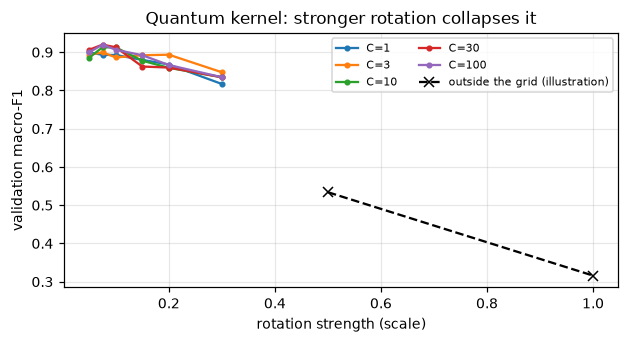

scale 0.5 / 1.0 -> {0.5: 0.534, 1.0: 0.316}


In [3]:
config = load_config()
if RUN_TUNING:
    rerun, log = tune.tune(write=False)
    print('rerun reproduces the frozen settings:', all(rerun[k] == config[k] for k in tune.GRIDS))
else:
    log = json.loads((OUT / 'tuning_log.json').read_text())
display(pd.DataFrame({k: dict(frozen_settings=config[k], configurations=v['configurations'], tuning_seconds=round(v['seconds'], 1),
                              best_validation_macro_f1=round(v['best_validation_macro_f1'], 4)) for k, v in log.items()}).T)

grid = pd.DataFrame(log['quantum']['rows'])
Z, Zv = prep.transform(X), prep.transform(Xv)
outside = {s: score(yv, QuantumKernelSVM(s, config['quantum']['C']).fit(Z, y).predict(Zv), L)['macro_f1'] for s in [0.5, 1.0]}
fig, ax = plt.subplots(figsize=(6.5, 3))
for C, g in grid.groupby('C'): ax.plot(g.scale, g.validation_macro_f1, marker='o', ms=3, label=f'C={C}')
ax.plot(list(outside), list(outside.values()), 'kx--', label='outside the grid (illustration)')
ax.set(xlabel='rotation strength (scale)', ylabel='validation macro-F1', title='Quantum kernel: stronger rotation collapses it')
ax.legend(fontsize=7, ncol=2); save_show(fig, 'cg_01_kernel_scale')
print('scale 0.5 / 1.0 ->', {k: round(v, 3) for k, v in outside.items()})

## 3. Main result: seeds 0, 1, 2 on validation, then frozen test predictions

The quantum-kernel SVM, the RBF SVM and the polynomial SVM are **deterministic**, so their results repeat across seeds; only the forest (and therefore the committees) depends on the seed. Times include preprocessing, statevector simulation, kernel construction and fitting. The supplied classical reference is refitted and checked against `results/reference_0_predictions.csv`.

In [4]:
ref, ref_fit = timed(lambda: reference().fit(X, y))
ref_pred, ref_predict = timed(lambda: ref.predict(Xv))
supplied = pd.read_csv(ROOT / 'results/reference_0_predictions.csv').set_index('sample_id').loc[ids_v]
assert (supplied.prediction.to_numpy() == ref_pred).all(), 'refitted reference differs from the supplied run'

records, P, fitted = [], {}, {}
def record(name, seed, pred, **extra):
    P[name, seed] = pred
    records.append(dict(model=name, seed=seed, **score(yv, pred, L), **extra))
    pd.DataFrame({'sample_id': ids_v, 'target': yv, 'prediction': pred}).to_csv(
        OUT / 'predictions' / f"{name.replace(' ', '_')}_{seed}_validation.csv", index=False)

for seed in SEEDS:
    record('reference', seed, ref_pred, fit_seconds=ref_fit, predict_seconds=ref_predict)
    for name, cls in [('quantum committee', Submission), ('matched control', MatchedControl)]:
        model, fit_s = timed(lambda: cls().fit(X, y, seed))
        ins, pred_s = timed(lambda: model.inspect(Xv))
        fitted[name, seed] = model
        record(name, seed, ins['prediction'], fit_seconds=fit_s, predict_seconds=pred_s, flagged=ins['flag'].mean(),
               accuracy_unflagged=(ins['prediction'] == yv)[~ins['flag']].mean())
        for member, votes in zip(model.names, ins['votes']):
            label = {'quantum': 'quantum SVM', 'poly': 'poly SVM', 'rbf': 'RBF SVM', 'forest': 'forest'}[member]
            if (label, seed) not in P: record(label, seed, votes, fit_seconds=model.fit_seconds[member])
        test = model.inspect(Xt)  # frozen settings, test features only
        pd.DataFrame({'sample_id': ids_t, 'prediction': test['prediction'], 'flag': test['flag'],
                      **{m: v for m, v in zip(model.names, test['votes'])}}).to_csv(
            OUT / 'predictions' / f"{name.replace(' ', '_')}_{seed}_test.csv", index=False)

runs = pd.DataFrame(records)
order = ['quantum committee', 'matched control', 'reference', 'quantum SVM', 'poly SVM', 'RBF SVM', 'forest']
for k, c in enumerate(L):
    runs[f'recall_{c}'] = runs.recall.str[k]; runs[f'precision_{c}'] = runs.precision.str[k]
cols = ['macro_f1', 'accuracy'] + [f'recall_{c}' for c in L] + [f'precision_{c}' for c in L] + ['flagged', 'accuracy_unflagged', 'fit_seconds', 'predict_seconds']
summary = runs.groupby('model')[cols].agg(['mean', lambda s: s.std(ddof=0)]).rename(columns={'<lambda_0>': 'sd'}).loc[order]
display(summary[['macro_f1', 'accuracy', 'flagged', 'accuracy_unflagged', 'fit_seconds']].round(4))
display(summary[[f'recall_{c}' for c in L] + [f'precision_{c}' for c in L]].xs('mean', axis=1, level=1).round(3))

macro_f1         accuracy         flagged          \
                      mean      sd     mean      sd    mean      sd   
model                                                                 
quantum committee   0.9214  0.0033   0.9222  0.0031  0.0911  0.0031   
matched control     0.9218  0.0032   0.9222  0.0031  0.0844  0.0031   
reference           0.8797  0.0000   0.8800  0.0000     NaN     NaN   
quantum SVM         0.9200  0.0000   0.9200  0.0000     NaN     NaN   
poly SVM            0.9269  0.0000   0.9267  0.0000     NaN     NaN   
RBF SVM             0.9326  0.0000   0.9333  0.0000     NaN     NaN   
forest              0.9040  0.0063   0.9044  0.0063     NaN     NaN   

                  accuracy_unflagged         fit_seconds          
                                mean      sd        mean      sd  
model                                                             
quantum committee             0.9633  0.0001      1.1043  0.0114  
matched control               0.9636  0.0001      1.0212  0.0202  
reference                        NaN     NaN      0.0243  0.0000  
quantum SVM                      NaN     NaN      0.1244  0.0058  
poly SVM                         NaN     NaN      0.0339  0.0006  
RBF SVM                          NaN     NaN      0.0375  0.0025  
forest                           NaN     NaN      0.9366  0.0095

,recall_alfalfa,recall_maize,recall_wheat,precision_alfalfa,precision_maize,precision_wheat
model,,,,,,
quantum committee,0.940,0.980,0.847,0.922,0.913,0.934
matched control,0.940,0.960,0.867,0.922,0.929,0.915
reference,0.940,0.860,0.840,0.887,0.915,0.840
quantum SVM,0.940,0.920,0.900,0.922,0.939,0.900
poly SVM,0.940,0.920,0.920,0.959,0.939,0.885
RBF SVM,0.960,0.980,0.860,0.941,0.925,0.935
forest,0.933,0.933,0.847,0.921,0.909,0.882


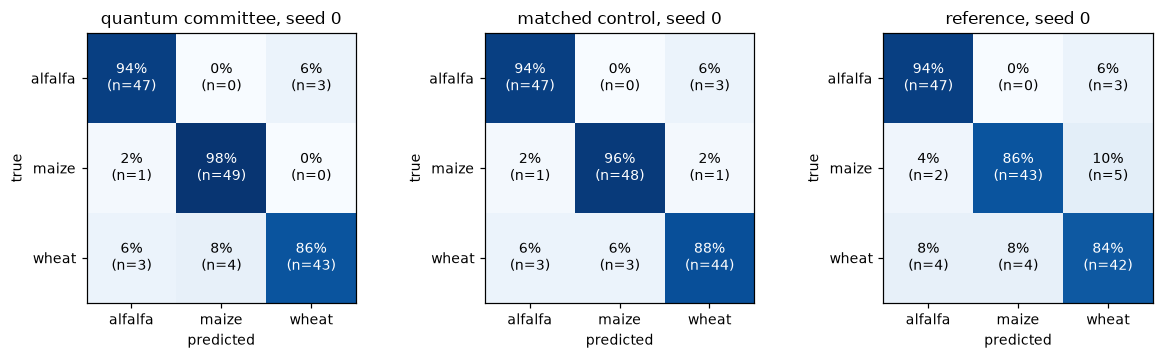

{
 "inputs": "13 raw features -> 8 train-fitted PCA numbers",
 "preprocessing_fitted_values": 159,
 "fit_seconds": {
  "preprocessing": 0.004822687998967012,
  "quantum": 0.13195856400125194,
  "rbf": 0.034579674997075927,
  "forest": 0.9442200250014139,
  "total": 1.1158932090002054
 },
 "members": {
  "quantum": {
   "qubits": 8,
   "feature_map_depth": 23,
   "feature_map_cx": 14,
   "kernel_circuit_cx": 28,
   "trainable_quantum": 0,
   "support_vectors": 222,
   "training_states_simulated": 914,
   "training_kernel_circuits": 417241,
   "circuits_per_predicted_field": 222,
   "kernel_storage_bytes": 6683168,
   "dual_coefficients": 444,
   "simulation": "exact statevector",
   "params": {
    "scale": 0.075,
    "C": 100
   }
  },
  "rbf": {
   "support_vectors": 200,
   "stored_values": 2000,
   "params": {
    "gamma": 0.06,
    "C": 30
   }
  },
  "forest": {
   "trees": 300,
   "total_nodes": 40454,
   "mean_depth": 11.233333333333333,
   "params": {
    "max_features": 2,
   

In [5]:
from sklearn.metrics import confusion_matrix
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
for ax, name in zip(axes, ['quantum committee', 'matched control', 'reference']):
    cm = confusion_matrix(yv, P[name, 0], labels=L); norm = cm / cm.sum(1, keepdims=True)
    ax.imshow(norm, vmin=0, vmax=1, cmap='Blues'); ax.grid(False)
    for i in range(3):
        for j in range(3): ax.text(j, i, f'{norm[i, j]:.0%}\n(n={cm[i, j]})', ha='center', va='center', color='white' if norm[i, j] > .55 else 'black')
    ax.set(xticks=range(3), yticks=range(3), xticklabels=L, yticklabels=L, xlabel='predicted', ylabel='true', title=f'{name}, seed 0')
fig.tight_layout(); save_show(fig, 'cg_02_confusion')

res_q, res_c = fitted['quantum committee', 0].resources(), fitted['matched control', 0].resources()
resources = {'quantum committee': res_q, 'matched control': res_c,
             'reference': dict(support_vectors=int(ref[-1].n_support_.sum()), inputs='13 raw features', params=json.loads((ROOT / 'configs/reference.json').read_text())['params'])}
print(json.dumps(res_q, indent=1, default=str))
print('matched control members:', json.dumps(res_c['members'], default=str))

**Resources, in words.** The quantum member uses **8 qubits**, a feature map of depth 23 with 14 CX gates (a kernel circuit is the map followed by the inverse map: 28 CX before compilation), **no trainable quantum angles** and 222 support vectors. Exact simulation computes one 256-amplitude statevector per field (914 for training), which stands in for the 417,241 compute-uncompute circuits a QPU would need for the training kernel; predicting one field on a QPU takes one circuit per support vector. The training kernel occupies 6.7 MB. Parameter matching is not required for kernels and trees, so we report support vectors, stored values, tree nodes and runtime instead.

## 4. Is any difference real? Paired spatial-block bootstrap

Both models are scored on the **same resampled validation spatial blocks** (`data/validation_groups.json`, 18 blocks, 2,000 resamples, seed 2026), averaging the three seeds. `delta` is the second model minus the first; a 95% interval that contains 0 means the data cannot tell the two apart.

In [6]:
W = guard.block_weights(ids_v)
stack = lambda name: np.array([P[name, s] for s in SEEDS])
pairs = [('matched control', 'quantum committee'), ('reference', 'quantum committee'), ('poly SVM', 'quantum SVM'),
         ('RBF SVM', 'quantum SVM'), ('RBF SVM', 'quantum committee')]
boot = pd.DataFrame([dict(first=a, second=b, **guard.paired_bootstrap(stack(a), stack(b), yv, W)) for a, b in pairs])
display(boot[['first', 'second', 'delta', 'ci95', 'share_positive']].round(4))
main = dict(summary=json.loads(summary.to_json()), records=json.loads(runs.drop(columns=['precision', 'recall', 'support']).to_json(orient='records')),
            bootstrap=json.loads(boot.to_json(orient='records')), resources=resources, config=config,
            main_run_seconds=time.perf_counter() - T0)
(OUT / 'main_results.json').write_text(json.dumps(main, indent=2, default=str))
print(f"main run (sections 1-4) took {main['main_run_seconds']:.0f} s including the optional tuning rerun")

,first,second,delta,ci95,share_positive
0,matched control,quantum committee,-0.0004,"[-0.019436, 0.023784]",0.3780
1,reference,quantum committee,0.0416,"[-0.000707, 0.09178]",0.9735
2,poly SVM,quantum SVM,-0.0069,"[-0.04201, 0.03875]",0.3495
3,RBF SVM,quantum SVM,-0.0126,"[-0.041945, 0.027744]",0.2330
4,RBF SVM,quantum committee,-0.0112,"[-0.032046, 0.005292]",0.1175


main run (sections 1-4) took 58 s including the optional tuning rerun


## 5. Additional analysis: the attack lab and the tamper alarm

All attacks work on **copies**; the submitted model always trains on the clean released labels.

* **Tampering** edits the **13 raw measurements** of a validation field, not the 8 PCA numbers, and the edit passes through the training-fitted preprocessing like a forged record would. The budget `ε` is an L2 norm in training standard deviations, and every band stays within the training range, so a tampered field remains plausible. The attack is a gradient-free random search (150 steps): a weak attacker, so measured damage is a lower bound.
  * **naive** attacker: fools the RBF SVM, the main classical inspector shared by both committees, so both committees see *identical* tampered fields.
  * **adaptive** attacker: knows all three inspectors and pushes down the largest of their margins.
* **Undetected** = all inspectors in the alarm agree on a wrong crop (the alarm stays silent). Lower is better.
* **Poisoned labels**: a fraction of training labels flipped at random (5 draws). **Missing bands**: k of 13 bands lost per field and replaced by the training mean (20 draws).

In [7]:
if RUN_ATTACK_LAB:
    t = time.perf_counter()
    tamper_rows, tamper_fields = guard.tamper_study(X, y, Xv, yv)
    poison_rows = guard.poison_study(X, y, Xv, yv)
    missing_rows = guard.missing_study(fitted['quantum committee', 0], fitted['matched control', 0], X, Xv, yv)
    rate = lambda attack, eps, name: np.array([tamper_fields[attack, eps, s, name] for s in SEEDS])
    lab_boot = [dict(attack=atk, eps=e, first=a, second=b, **guard.paired_bootstrap(rate(atk, e, a), rate(atk, e, b), yv, W, stat='rate'))
                for atk, a, b in [('naive', '+ poly SVM', '+ quantum SVM'), ('naive', 'matched control', 'quantum committee'),
                                  ('adaptive', 'matched control', 'quantum committee')] for e in (0.05, 0.1, 0.2, 0.5)]
    lab = dict(tamper_rows=tamper_rows, poison_rows=poison_rows, missing_rows=missing_rows, bootstrap=lab_boot,
               seconds=time.perf_counter() - t)
    (OUT / 'attack_lab.json').write_text(json.dumps(lab, indent=1, default=float))
else:
    lab = json.loads((OUT / 'attack_lab.json').read_text())
tr = pd.DataFrame(lab['tamper_rows'])
alarms = ['RBF SVM alone', '+ quantum SVM', '+ poly SVM', '+ forest', 'quantum committee', 'matched control']
naive = tr[tr.attack.isin(['none', 'naive'])]
print('Undetected (wrong and unanimous), mean of 3 seeds; eps 0 = clean fields')
display(naive.pivot_table(index='alarm', columns='eps', values='undetected').loc[alarms].round(3))
print('Flagged for a human')
display(naive.pivot_table(index='alarm', columns='eps', values='flagged').loc[alarms].round(3))
print('Accuracy of each inspector on fields tampered against the RBF SVM (transfer)')
display(tr[tr.attack == 'naive transfer'].pivot_table(index='alarm', columns='eps', values='accuracy').round(3))
print('Adaptive attacker (knows all three inspectors)')
display(tr[tr.attack == 'adaptive'].pivot_table(index='alarm', columns='eps', values=['undetected', 'flagged', 'accuracy']).round(3))

Undetected (wrong and unanimous), mean of 3 seeds; eps 0 = clean fields


eps,0.00,0.05,0.10,0.20,0.50
alarm,,,,,
RBF SVM alone,0.067,0.180,0.249,0.493,0.971
+ quantum SVM,0.040,0.109,0.187,0.358,0.784
+ poly SVM,0.040,0.140,0.218,0.400,0.887
+ forest,0.051,0.136,0.153,0.196,0.313
quantum committee,0.033,0.089,0.127,0.182,0.264
matched control,0.033,0.124,0.147,0.187,0.307


Flagged for a human


eps,0.00,0.05,0.10,0.20,0.50
alarm,,,,,
RBF SVM alone,0.000,0.000,0.000,0.000,0.000
+ quantum SVM,0.060,0.113,0.122,0.184,0.196
+ poly SVM,0.053,0.062,0.056,0.109,0.096
+ forest,0.053,0.047,0.104,0.302,0.658
quantum committee,0.091,0.136,0.191,0.364,0.716
matched control,0.084,0.080,0.136,0.322,0.676


Accuracy of each inspector on fields tampered against the RBF SVM (transfer)


eps,0.05,0.10,0.20,0.50
alarm,,,,
RBF SVM,0.820,0.751,0.507,0.029
forest,0.856,0.827,0.784,0.656
poly SVM,0.824,0.738,0.567,0.080
quantum SVM,0.842,0.738,0.549,0.116


Adaptive attacker (knows all three inspectors)


accuracy                      flagged                       \
eps                   0.05   0.10   0.20   0.50    0.05   0.10   0.20   0.50   
alarm                                                                          
matched control      0.840  0.782  0.596  0.122   0.069  0.116  0.216  0.360   
quantum committee    0.844  0.778  0.593  0.171   0.122  0.138  0.311  0.409   

                  undetected                       
eps                     0.05   0.10   0.20   0.50  
alarm                                              
matched control        0.127  0.160  0.240  0.549  
quantum committee      0.089  0.153  0.233  0.504

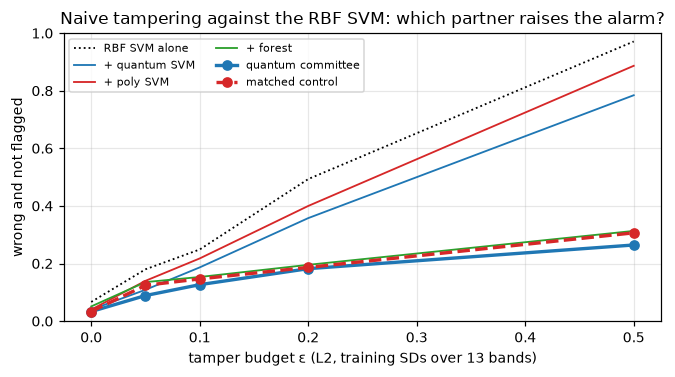

Paired bootstrap of the undetected rate (second minus first; negative = second lets fewer through)


,attack,eps,first,second,delta,ci95,share_positive
0,naive,0.05,+ poly SVM,+ quantum SVM,-0.031,"[-0.093531, 0.016671]",0.100
1,naive,0.10,+ poly SVM,+ quantum SVM,-0.031,"[-0.084447, 0.016132]",0.084
2,naive,0.20,+ poly SVM,+ quantum SVM,-0.042,"[-0.132135, 0.025137]",0.114
3,naive,0.50,+ poly SVM,+ quantum SVM,-0.102,"[-0.169043, -0.045659]",0.000
4,naive,0.05,matched control,quantum committee,-0.036,"[-0.086498, 0.005995]",0.044
5,naive,0.10,matched control,quantum committee,-0.020,"[-0.049594, -0.002347]",0.000
6,naive,0.20,matched control,quantum committee,-0.004,"[-0.015724, 0.00509]",0.135
7,naive,0.50,matched control,quantum committee,-0.042,"[-0.094152, -0.004784]",0.012
8,adaptive,0.05,matched control,quantum committee,-0.038,"[-0.090929, 0.005594]",0.030
9,adaptive,0.10,matched control,quantum committee,-0.007,"[-0.025424, 0.0]",0.000


In [8]:
fig, ax = plt.subplots(figsize=(7, 3.4))
for name, style in zip(alarms, ['k:', 'C0-', 'C3-', 'C2-', 'C0-o', 'C3--o']):
    g = naive[naive.alarm == name].groupby('eps').undetected.mean()
    ax.plot(g.index, g.values, style, lw=2.2 if 'o' in style else 1.2, label=name)
ax.set(xlabel='tamper budget ε (L2, training SDs over 13 bands)', ylabel='wrong and not flagged', ylim=(0, 1),
       title='Naive tampering against the RBF SVM: which partner raises the alarm?')
ax.legend(fontsize=7, ncol=2); save_show(fig, 'cg_03_tamper_alarm')
print('Paired bootstrap of the undetected rate (second minus first; negative = second lets fewer through)')
display(pd.DataFrame(lab['bootstrap'])[['attack', 'eps', 'first', 'second', 'delta', 'ci95', 'share_positive']].round(3))

In [9]:
pr = pd.DataFrame(lab['poison_rows'])
print('Poisoned training labels: validation macro-F1, mean of 5 draws')
display(pr.pivot_table(index='model', columns='rate', values='macro_f1').loc[order[:2] + order[3:]].round(3))
mr = pd.DataFrame(lab['missing_rows'])
print('Missing bands at prediction time: macro-F1 and alarm, mean of 20 draws')
display(mr[mr.macro_f1.notna()].pivot_table(index='model', columns='missing', values='macro_f1').loc[order[:2] + order[3:]].round(3))
display(mr[mr.macro_f1.isna()].pivot_table(index='model', columns='missing', values=['flagged', 'undetected']).round(3))

Poisoned training labels: validation macro-F1, mean of 5 draws


rate,0.1,0.2,0.3
model,,,
quantum committee,0.892,0.880,0.844
matched control,0.889,0.885,0.856
quantum SVM,0.862,0.829,0.783
poly SVM,0.878,0.878,0.845
RBF SVM,0.900,0.880,0.841
forest,0.879,0.868,0.849


Missing bands at prediction time: macro-F1 and alarm, mean of 20 draws


missing,1,2,4
model,,,
quantum committee,0.825,0.765,0.667
matched control,0.808,0.743,0.632
quantum SVM,0.752,0.671,0.564
poly SVM,0.775,0.696,0.572
RBF SVM,0.796,0.717,0.605
forest,0.869,0.842,0.777


flagged               undetected              
missing                       1      2      4          1      2      4
model                                                                 
matched control alarm     0.219  0.307  0.431      0.059  0.064  0.085
quantum committee alarm   0.270  0.383  0.519      0.056  0.057  0.067

## 6. Additional analysis: quantum noise and the AI error-fixer (needs `qiskit-aer`)

A real device returns noisy similarity values. Because 8 qubits are cheap to simulate exactly, the true value of any training pair is known, so a **linear regression learns noisy → exact** on calibration pairs and corrects pairs it never saw. Zero-noise extrapolation (ZNE, every CX tripled, then extrapolated to zero noise) is the classical baseline; it costs twice the circuits. Simulated device: gate and readout errors with T1/T2 decay (`challenge/mitigation.py`), 1×–3× the base error rates, 1024 shots, on a small subset (40 training × 30 validation fields; 200 calibration pairs of other training fields).

,mae_raw,mae_zne,mae_fixed,fixer_slope,fixer_intercept,f1_exact,f1_raw,f1_fixed,circuits,depth,cx
level,,,,,,,,,,,
1,0.1002,0.0583,0.0134,1.4692,-0.0032,0.6,0.6000,0.6351,3380,51,28
2,0.1674,0.1228,0.0190,2.1413,-0.0071,0.6,0.6000,0.7411,3380,51,28
3,0.2125,0.1754,0.0242,3.1103,-0.0153,0.6,0.5331,0.7434,3380,51,28


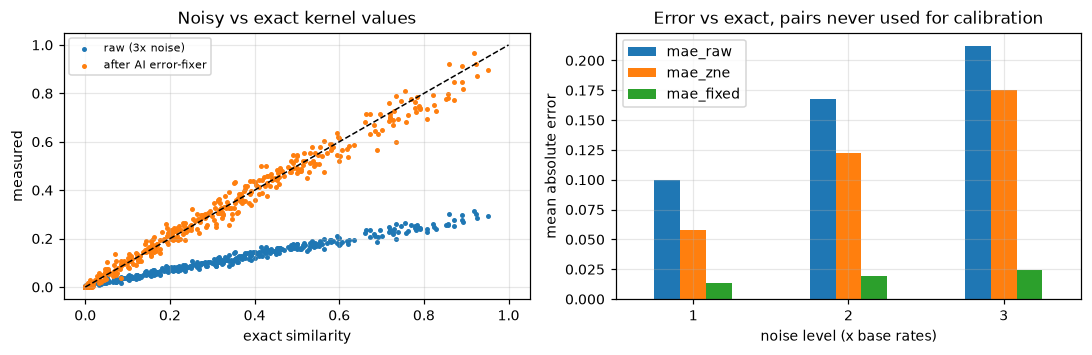

In [10]:
try:
    import qiskit_aer  # optional extra: requirements-noise.txt
    have_aer = True
except ImportError:
    have_aer = False
if RUN_NOISE_STUDY and have_aer:
    sub0 = fitted['quantum committee', 0]
    noise, noise_s = timed(lambda: mitigation.noise_study(sub0.members[0], sub0.transform(X), y, sub0.transform(Xv), yv))
    noise['seconds'] = noise_s
    (OUT / 'noise_study.json').write_text(json.dumps(noise))
else:
    print('qiskit-aer not installed or study switched off: showing the saved study')
    noise = json.loads((OUT / 'noise_study.json').read_text())
nr = pd.DataFrame(noise['rows']).set_index('level')
display(nr[['mae_raw', 'mae_zne', 'mae_fixed', 'fixer_slope', 'fixer_intercept', 'f1_exact', 'f1_raw', 'f1_fixed', 'circuits', 'depth', 'cx']].round(4))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
r = noise['rows'][-1]
axes[0].scatter(r['sample_exact'], r['sample_raw'], s=5, label=f"raw ({r['level']}x noise)")
axes[0].scatter(r['sample_exact'], r['sample_fixed'], s=5, label='after AI error-fixer')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1); axes[0].set(xlabel='exact similarity', ylabel='measured', title='Noisy vs exact kernel values'); axes[0].legend(fontsize=7)
nr[['mae_raw', 'mae_zne', 'mae_fixed']].plot.bar(ax=axes[1], rot=0)
axes[1].set(xlabel='noise level (x base rates)', ylabel='mean absolute error', title='Error vs exact, pairs never used for calibration')
fig.tight_layout(); save_show(fig, 'cg_04_noise_fixer')

## 7. IBM hardware bonus: inference only, compared with the exact simulator

The committee is trained locally and frozen; the QPU only measures the compute-uncompute similarity circuits between a few validation fields and the quantum SVM's support vectors. Nothing is trained on hardware. Four fields: one typical verified field per crop and one field tampered at ε = 0.1 that fools the RBF SVM while the exact quantum SVM still answers correctly (so the alarm fires). 40 calibration pairs of training fields ride in the same job, so the AI error-fixer is fitted **on that device in that session**. The token is read from `QISKIT_IBM_TOKEN` only; it never appears in this notebook, the outputs or git.

The first run used the **submitted** model (C = 100). The offline scan below then explains its result and selects a hardware-ready variant (largest C whose simulated agreement under the measured hardware error is at least 95%), which a second job checked. **This is one small fixed-model inference example per model, not an accuracy estimate.**

,hardware_result.json,hardware_result_robust.json
backend,ibm_fez,ibm_marrakesh
job_id,dc01nteq4uuc73a1tkq0,dc01qrts2omc7388k9h0
finished_utc,2026-11-20T10:11:03+00:00,2026-11-20T10:18:02+00:00
shots,512,512
circuits,928,1240
support_vectors,222,300
calibration_pairs,40,40
transpiled_depth,102,99
transpiled_two_qubit_gates,26,26
physical_qubits,"[141, 142, 143, 144, 145, 146, 147, 137]","[27, 17, 7, 6, 5, 4, 3, 2]"


name   target  \
hardware_result.json        0             clean alfalfa  alfalfa   
                            1               clean maize    maize   
                            2               clean wheat    wheat   
                            3  tampered wheat (eps 0.1)    wheat   
hardware_result_robust.json 0             clean alfalfa  alfalfa   
                            1               clean maize    maize   
                            2               clean wheat    wheat   
                            3  tampered wheat (eps 0.1)    wheat   

                              quantum_exact quantum_hardware_raw  \
hardware_result.json        0       alfalfa              alfalfa   
                            1         maize              alfalfa   
                            2         wheat              alfalfa   
                            3         wheat                maize   
hardware_result_robust.json 0       alfalfa              alfalfa   
                            1         maize                maize   
                            2         wheat                wheat   
                            3         wheat                maize   

                              quantum_hardware_fixed      rbf   forest  
hardware_result.json        0                alfalfa  alfalfa  alfalfa  
                            1                alfalfa    maize    maize  
                            2                alfalfa    wheat    wheat  
                            3                  maize  alfalfa  alfalfa  
hardware_result_robust.json 0                alfalfa  alfalfa  alfalfa  
                            1                  maize    maize    maize  
                            2                  wheat    wheat    wheat  
                            3                  wheat    maize    maize

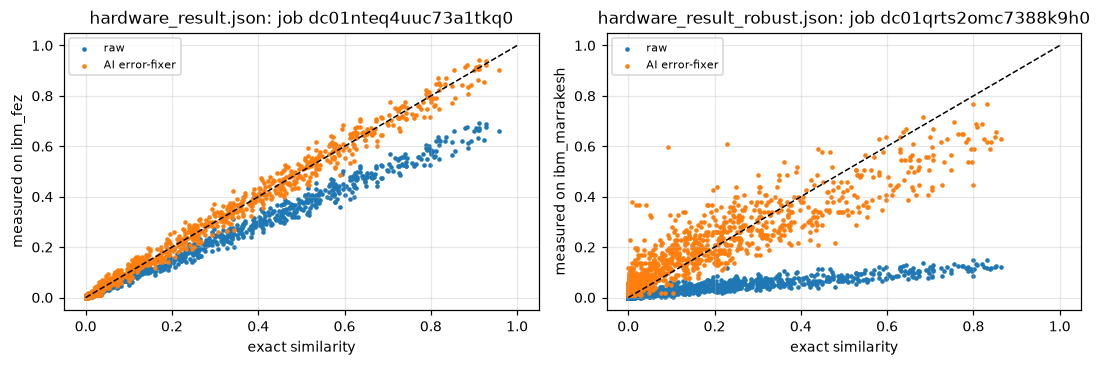

In [11]:
HARDWARE_RUNS = {'hardware_result.json': None, 'hardware_result_robust.json': 1}  # file -> quantum C override (None = submitted model)
if RUN_HARDWARE:
    for file, C in HARDWARE_RUNS.items():
        cfg = load_config()
        if C: cfg['quantum'] = dict(cfg['quantum'], C=C)
        model = Submission(cfg).fit(X, y, 0)
        hk.run(model, hk.pick_fields(model, X, Xv, yv, ids_v), hk.connect(), shots=512, n_cal=40, approved=True, save=OUT / file)
hw = {f: json.loads((OUT / f).read_text()) for f in HARDWARE_RUNS if (OUT / f).exists()}
keys = ['backend', 'job_id', 'finished_utc', 'shots', 'circuits', 'support_vectors', 'calibration_pairs', 'transpiled_depth',
        'transpiled_two_qubit_gates', 'physical_qubits', 'quantum_seconds', 'mae_raw', 'mae_fixed', 'fixer_slope', 'fixer_intercept']
display(pd.DataFrame({f: {k: h[k] for k in keys} for f, h in hw.items()}))
display(pd.concat({f: pd.DataFrame(h['fields'])[['name', 'target', 'quantum_exact', 'quantum_hardware_raw', 'quantum_hardware_fixed', 'rbf', 'forest']]
                   for f, h in hw.items()}))
fig, axes = plt.subplots(1, len(hw), figsize=(5 * len(hw), 3.4), squeeze=False)
for ax, (f, h) in zip(axes[0], hw.items()):
    n = h['support_vectors'] * len(h['fields']); ex, me = np.array(h['exact']), np.array(h['measured'])
    ax.scatter(ex[:n], me[:n], s=4, label='raw')
    ax.scatter(ex[:n], np.clip(h['fixer_slope'] * me[:n] + h['fixer_intercept'], 0, 1), s=4, label='AI error-fixer')
    ax.plot([0, 1], [0, 1], 'k--', lw=1); ax.legend(fontsize=7)
    ax.set(xlabel='exact similarity', ylabel=f"measured on {h['backend']}", title=f"{f}: job {h['job_id']}")
fig.tight_layout(); save_show(fig, 'cg_05_ibm_hardware')

,support_vectors,max_dual,exact_macro_f1,agree_shot_noise,agree_hardware_error
C,,,,,
0.3,395,0.3,0.893,0.994,0.981
1.0,300,1.0,0.893,0.978,0.968
3.0,265,3.0,0.900,0.933,0.892
10.0,230,10.0,0.913,0.796,0.730
30.0,225,30.0,0.920,0.625,0.555
100.0,222,100.0,0.920,0.482,0.445


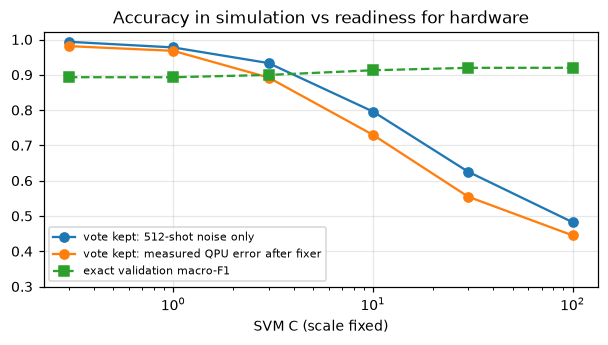

In [12]:
# Why did the submitted model's votes not survive the QPU? Large C means large dual coefficients that amplify kernel errors.
# Offline (no QPU): resample the measured post-fixer hardware errors of the C=100 run, or 512-shot sampling noise.
q = fitted['quantum committee', 0].members[0]
scan = hk.robustness_scan(Z, y, Zv, yv, hk.residuals(hw['hardware_result.json']), q.scale)
(OUT / 'hardware_robustness.json').write_text(json.dumps(dict(rows=scan, source='hardware_result.json residuals after the AI error-fixer'), indent=1))
sc = pd.DataFrame(scan).set_index('C'); display(sc.round(3))
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.semilogx(sc.index, sc.agree_shot_noise, 'o-', label='vote kept: 512-shot noise only')
ax.semilogx(sc.index, sc.agree_hardware_error, 'o-', label='vote kept: measured QPU error after fixer')
ax.semilogx(sc.index, sc.exact_macro_f1, 's--', label='exact validation macro-F1')
ax.set(xlabel='SVM C (scale fixed)', ylim=(0.3, 1.02), title='Accuracy in simulation vs readiness for hardware'); ax.legend(fontsize=7)
save_show(fig, 'cg_06_hardware_readiness')

## 8. Findings

*Every number below is printed by a cell above or stored in `outputs/`. Validation numbers are optimistic for every model alike, because the same 150 fields chose the settings.*

**Answer to the question.** On clean data the quantum member adds nothing measurable over an equally tuned classical one. Under tampering, the quantum partner raises the alarm slightly more often than the polynomial partner (a small gain, detectable at some budgets only, paid for with more flags), but a *classical forest* partner matters far more. On its own, the quantum SVM is not more robust. On real hardware, the model that wins in exact simulation is not the model that survives the device.

1. **Clean comparison (main result).** Quantum committee 0.9214 ± 0.0033 macro-F1 (92.2% accuracy) vs matched control 0.9218 ± 0.0032; paired bootstrap −0.0004, 95% interval [−0.019, +0.024]: no detectable difference. Both beat the supplied reference (0.8797) by about 0.042, with an interval [−0.001, +0.092] that just touches zero. The best single model is the RBF SVM (0.933); the vote costs about one point (interval [−0.032, +0.005]), and earns its place through the alarm: 9.1% of clean fields are flagged, and 96.3% of the unflagged ones are right.
2. **Tampering is cheap.** PC5–PC8 hold 0.1–0.4% of the variance each, yet the second scaler stretches them 11–23× relative to PC1, so the attacker edits the bands along those directions. Moving a field by only 0.2 training SDs in total fools the RBF SVM silently on 49% of fields; at 0.5 SDs on 97%. The extra accuracy of the 8-component view comes with this fragility.
3. **The alarm.** At ε = 0.1, 24.9% of fields slip through the RBF SVM alone, 18.7% with a quantum partner, 21.8% with a polynomial partner, 15.3% with the forest, 12.7% through the full quantum committee and 14.7% through the matched control. The quantum committee also flags more (19.1% vs 13.6%). Paired bootstrap, quantum minus control: −2.0 points [−5.0, −0.2] at ε = 0.1 and −4.2 [−9.4, −0.5] at ε = 0.5, but no detectable difference at ε = 0.05 or 0.2. With 12 such comparisons, read single intervals with care. At ε = 0.2 the forest cuts slips from 49% to 20%, while the quantum SVM gets to 36% and the poly SVM to 40%: smooth kernels are fooled together, and diversity of inductive bias matters more than quantumness. An attacker who knows all three inspectors still gets 50% (quantum) and 55% (control) of fields through at ε = 0.5.
4. **The quantum SVM alone is not more robust.** On fields tampered against the RBF SVM its accuracy tracks the poly SVM (0.738 vs 0.738 at ε = 0.1). With 30% poisoned labels it falls to 0.783 (poly 0.845, RBF 0.841, forest 0.849), and with 4 of 13 bands missing to 0.564 (poly 0.572, RBF 0.605, forest 0.777). The committees hold up better (0.844 / 0.856 with poisoning; 0.667 / 0.632 with 4 missing bands, the quantum committee flagging 52% vs 43%). Poisoning and missing-band results are descriptive: no bootstrap was run for them.
5. **AI error-fixer (simulated device).** One straight line fitted on 200 calibration pairs cuts the similarity error from 0.100 to 0.013 (1× noise), 0.167 to 0.019 (2×) and 0.213 to 0.024 (3×), beating zero-noise extrapolation (0.058 / 0.123 / 0.175), which costs twice the circuits. The 30-field classification check (exact 0.600, raw up to 0.600, fixed up to 0.743) is far too small to support any accuracy claim.
6. **IBM hardware.** `ibm_fez` (job `dc01nteq4uuc73a1tkq0`, submitted model, C = 100): the in-job error-fixer cut the kernel error from 0.073 to 0.018, yet only 1 of 4 quantum votes matched the exact simulator. The offline scan explains why: large C means dual weights up to 100, and 512-shot noise alone keeps only 48% of this model's validation votes (44.5% under the measured hardware error). Rule set before the second job: the largest C that keeps at least 95% of votes under the measured error, which is C = 1 (96.8%; exact macro-F1 0.893 instead of 0.920). `ibm_marrakesh` (job `dc01qrts2omc7388k9h0`, C = 1): 4 of 4 votes matched. On the tampered field the raw hardware vote was wrong (maize) and the error-fixer restored it (wheat), so the alarm fired on a real device. Both runs: 8 qubits, 26 two-qubit gates and depth about 100 after compilation, 512 shots; one small example each, not an accuracy estimate.

**Tuning effort, stated for every model.** One grid of 30 configurations per inspector on validation macro-F1: quantum 4.4 s, poly 1.4 s, RBF 1.3 s, forest 37.9 s (this run; `outputs/tuning_log.json` lists every configuration). The test-set predictions use these frozen settings only. The C = 1 hardware variant was chosen by the rule above for the hardware demo only and is not the submitted model. During development we also scanned the tamper budgets to place ε where the curves are informative.

**Runtime and machine.** Main run (sections 1–4, including the tuning rerun): about 1 minute. Whole notebook: about 11 minutes. Intel Core i5-8350U (8 threads, no GPU), 15 GB RAM, CPython 3.15.2 with the pinned packages. Peak memory 0.9 GB.

**Limitations.** Settings were chosen and scored on the same 150 validation fields. Attacks are a weak gradient-free search on 13 bands within the training range; NDVI is not kept consistent with B4/B8. The noise study is a simulated device on a small subset; real devices drift, so the error-fixer must be recalibrated each session (we did so inside each job). The error-fixer needs exact simulation for its labels, which works only for small circuits. Results cover one region, one date and three crops.

**We do not claim** a quantum advantage of any kind; that the quantum model is more robust than a classical one; that the alarm stops an attacker who knows the defence; that the error-fixer improves final accuracy; or that the hardware runs measure accuracy.

**Reused code and methods.** Organizers' starter (`challenge/data.py`, `classical.py`, `metrics.py`, `coverage.py`; `metric_vector` reused for the bootstrap). Qiskit `zz_feature_map` and `Statevector` (our closed form is checked against them in `tests/`), scikit-learn, qiskit-aer, qiskit-ibm-runtime. Quantum kernels: Havlíček et al. 2019; classical–quantum ensembles: Grossi et al. 2022; shot noise and SVM robustness: Shastry et al. 2022; learned error mitigation: Czarnik et al. 2020, Liao et al. 2023; benchmarking practice: Bowles et al. 2024; adversarial remote sensing: Czaja et al. 2018. Full links in the README and the project plan.

In [13]:
print(f'notebook total runtime: {time.perf_counter() - T0:.0f} s')
print('outputs:', sorted(p.name for p in OUT.glob('*.json')), '| predictions:', len(list((OUT / 'predictions').glob('*.csv'))), 'csv files')

notebook total runtime: 632 s
outputs: ['attack_lab.json', 'hardware_result.json', 'hardware_result_robust.json', 'hardware_robustness.json', 'main_results.json', 'noise_study.json', 'tuning_log.json'] | predictions: 27 csv files
